# Exploratory data analysis: daily prices

> **Author:** Floris Snelders. Per-ticker descriptive statistics and four overview figures for the 100-stock universe: price series, the return distribution, missing trading days and the up/down class balance. Figures are saved to `results/figures/eda/`. Merged from two earlier notebooks (descriptive statistics and visualisations) and pointed at the shared data loader. The outputs shown were produced on the original course dataset.

In [1]:
import sys
from pathlib import Path
sys.path.append("..")

import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data_utils import standardize
from src.datasets import load_prices

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

FIGURES = Path("../results/figures/eda")
FIGURES.mkdir(parents=True, exist_ok=True)
STATS_CSV = Path("../data/processed/eda_summary_stats.csv")  # derived from the data, so kept out of git

prices = standardize(load_prices())
prices["Date"] = prices["date"].dt.tz_localize(None).dt.normalize()
all_tickers = sorted(prices["ticker"].unique())
print(f"{len(all_tickers)} tickers | {len(prices):,} rows | "
      f"{prices['Date'].min().date()} -> {prices['Date'].max().date()}")


def load_ticker(ticker):
    """Daily rows of one ticker, deduplicated and sorted by date."""
    df = prices.loc[prices["ticker"] == ticker, ["Date", "close"]].rename(columns={"close": "Close"})
    return df.drop_duplicates(subset="Date").sort_values("Date").reset_index(drop=True)


def daily_close(df):
    """Daily closing price (last close of each trading day)."""
    return df.set_index("Date")["Close"].resample("D").last().dropna()


def daily_returns(daily):
    return daily.pct_change().dropna()

100 tickers | 224,030 rows | 2015-02-17 -> 2025-02-13


## 1. Descriptive statistics per ticker

In [2]:
# Reference calendar for the missing-days count: the union of all observed trading days
all_daily_sets = {t: set(daily_close(load_ticker(t)).index.date) for t in all_tickers}
all_trading_days = sorted(set().union(*all_daily_sets.values()))

records = []
for ticker in all_tickers:
    df = load_ticker(ticker)
    dc = daily_close(df)
    ret = daily_returns(dc)
    date_min, date_max = df["Date"].min(), df["Date"].max()
    ref_in_range = [d for d in all_trading_days if date_min.date() <= d <= date_max.date()]
    missing_days = len([d for d in ref_in_range if d not in all_daily_sets[ticker]])
    pct_up = (ret > 0).mean() * 100
    records.append({
        "Ticker": ticker,
        "Rows": len(df),
        "Date Start": date_min.date(),
        "Date End": date_max.date(),
        "Missing Days": missing_days,
        "Mean Daily Return": round(ret.mean(), 6),
        "Std Daily Return": round(ret.std(), 6),
        "Pct Up Days (%)": round(pct_up, 2),
        "Pct Down/Flat (%)": round(100 - pct_up, 2),
    })

stats_df = pd.DataFrame(records)
STATS_CSV.parent.mkdir(parents=True, exist_ok=True)
stats_df.to_csv(STATS_CSV, index=False)
print(f"{len(stats_df)} tickers | full history (2015-02-17 start): {(stats_df['Date Start'].astype(str) == '2015-02-17').sum()} "
      f"| tickers with missing days: {(stats_df['Missing Days'] > 0).sum()}")
stats_df.describe().round(4)

100 tickers | full history (2015-02-17 start): 75 | tickers with missing days: 7


,Rows,Missing Days,Mean Daily Return,Std Daily Return,Pct Up Days (%),Pct Down/Flat (%)
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
mean,2240.3000,19.7600,0.0070,0.2331,52.4019,47.5981
std,556.5529,147.1631,0.0521,1.7542,1.5483,1.5483
min,356.0000,0.0000,-0.0007,0.0118,48.7700,43.7500
25%,2466.2500,0.0000,0.0005,0.0171,51.2925,46.6600
50%,2515.0000,0.0000,0.0009,0.0205,52.5600,47.4400
75%,2515.0000,0.0000,0.0012,0.0297,53.3400,48.7075
max,2515.0000,1391.0000,0.5174,17.2954,56.2500,51.2300


In [3]:
# Shortest histories (recent IPOs / later index additions) and most missing days
display(stats_df.sort_values("Rows").head(8)[["Ticker", "Rows", "Date Start", "Missing Days"]])
display(stats_df.sort_values("Missing Days", ascending=False).head(5)[["Ticker", "Rows", "Missing Days"]])

,Ticker,Rows,Date Start,Missing Days
13,ARM,356,2023-09-14,0
43,GEHC,530,2023-01-04,0
96,WBD,714,2022-04-11,0
24,CEG,761,2022-02-02,0
63,META,821,2021-06-30,90
44,GFS,827,2021-10-28,0
1,ABNB,1049,2020-12-10,0
35,DASH,1050,2020-12-09,0


,Ticker,Rows,Missing Days
12,APP,1124,1391
16,AXON,1945,490
63,META,821,90
18,BIIB,2513,2
83,REGN,2514,1


## 2. Price series of five representative tickers

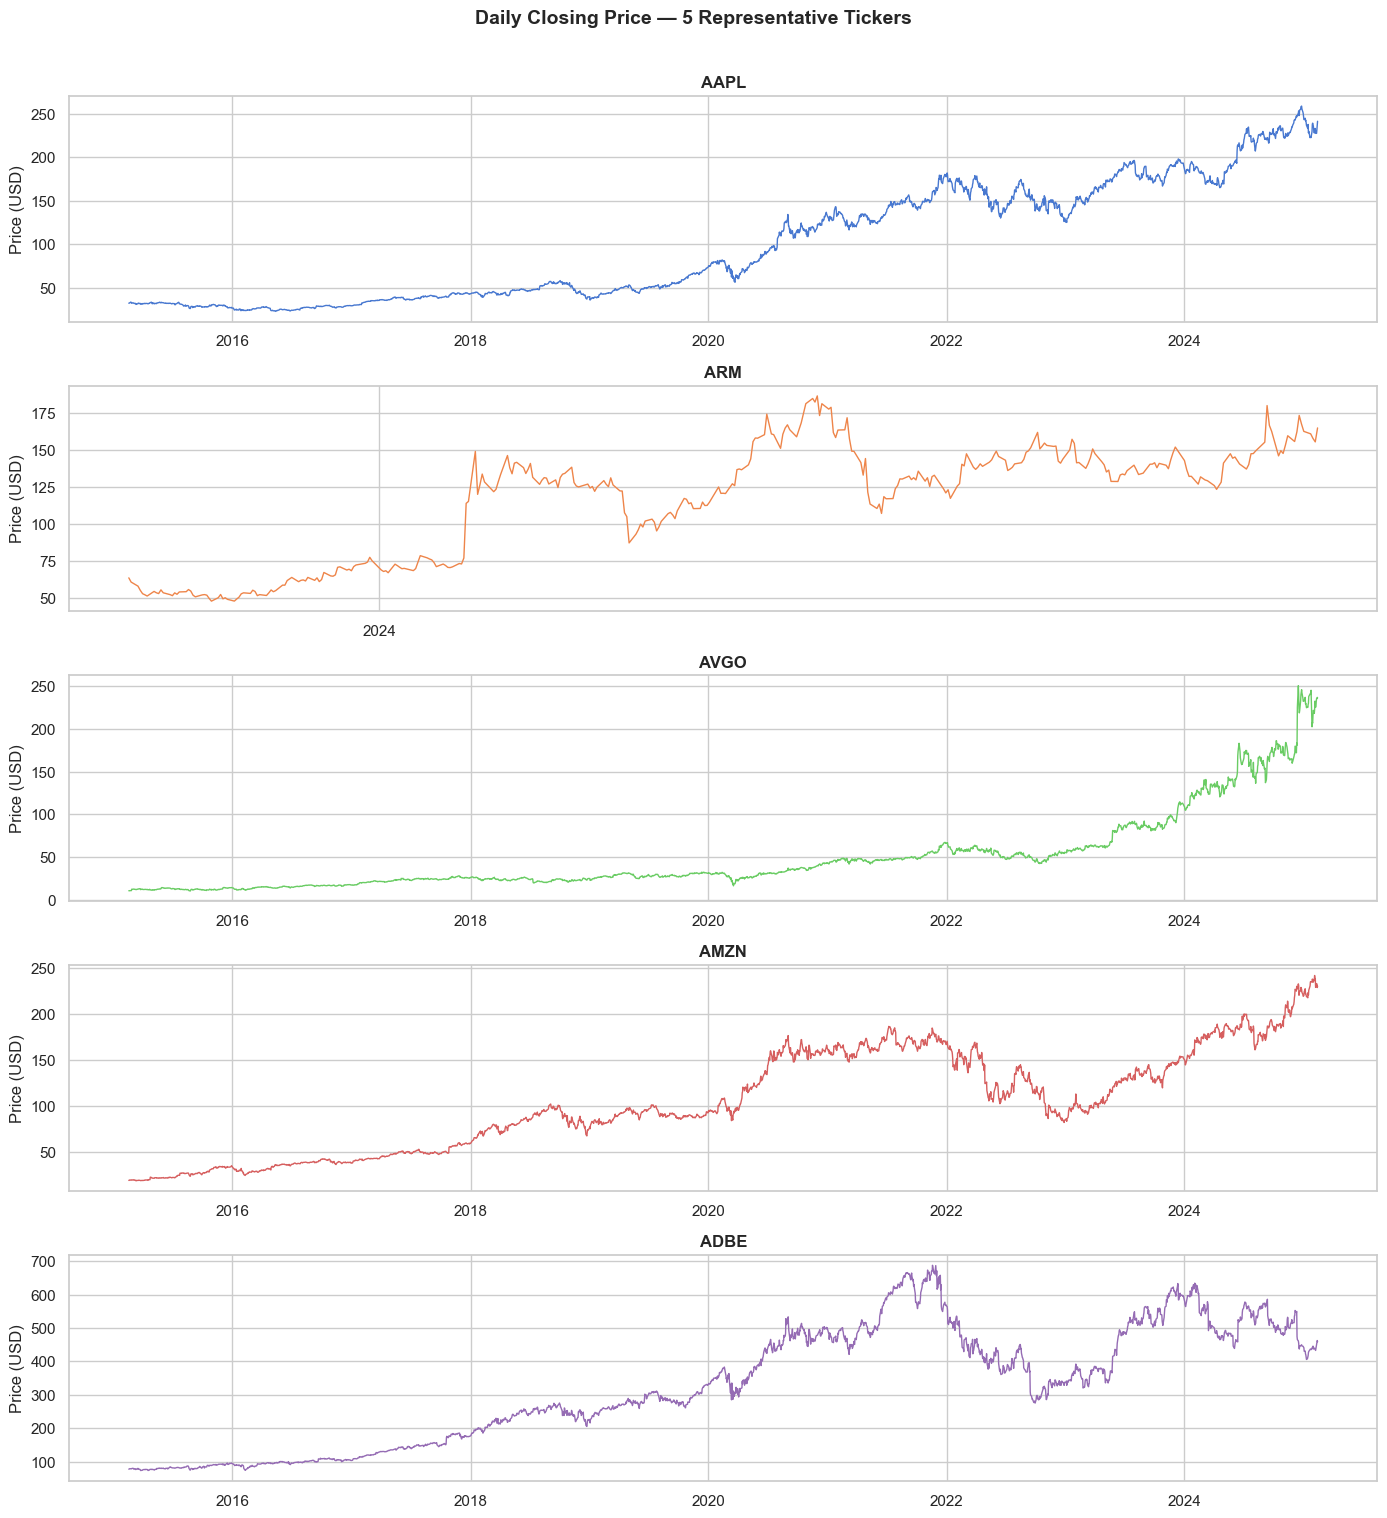

In [4]:
SAMPLE_TICKERS = [t for t in ["AAPL", "ARM", "AVGO", "AMZN", "ADBE"] if t in all_tickers][:5]

fig, axes = plt.subplots(len(SAMPLE_TICKERS), 1, figsize=(14, 3 * len(SAMPLE_TICKERS)), sharex=False)
fig.suptitle("Daily Closing Price — 5 Representative Tickers", fontsize=14, fontweight="bold", y=1.01)
for i, (ax, ticker) in enumerate(zip(axes, SAMPLE_TICKERS)):
    dc = daily_close(load_ticker(ticker))
    ax.plot(dc.index, dc.values, linewidth=1.0, color=sns.color_palette("muted")[i])
    ax.set_title(ticker, fontweight="bold")
    ax.set_ylabel("Price (USD)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.tight_layout()
plt.savefig(FIGURES / "01_price_series_daily.png", bbox_inches="tight", dpi=150)
plt.show()

## 3. Return distribution (all tickers aggregated)

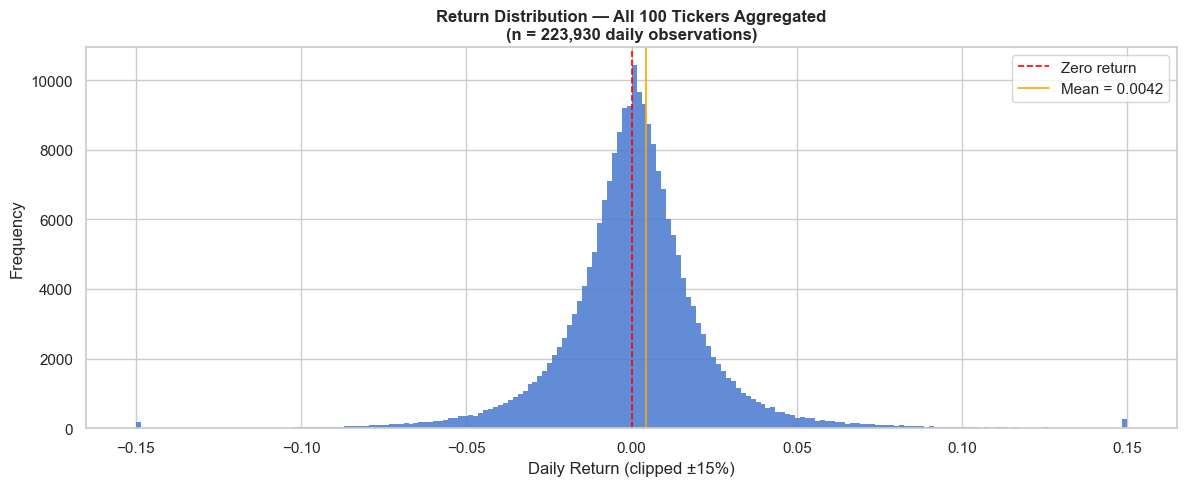

In [5]:
combined_returns = pd.concat(
    [daily_returns(daily_close(load_ticker(t))).rename(t) for t in all_tickers]
).dropna()
clipped = combined_returns.clip(-0.15, 0.15)  # clip extreme outliers for readability

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(clipped, bins=200, color=sns.color_palette("muted")[0], edgecolor="none", alpha=0.85)
ax.axvline(0, color="red", linewidth=1.2, linestyle="--", label="Zero return")
ax.axvline(combined_returns.mean(), color="orange", linewidth=1.2, linestyle="-",
           label=f"Mean = {combined_returns.mean():.4f}")
ax.set_xlabel("Daily Return (clipped ±15%)")
ax.set_ylabel("Frequency")
ax.set_title(f"Return Distribution — All {len(all_tickers)} Tickers Aggregated\n"
             f"(n = {len(combined_returns):,} daily observations)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "02_return_distribution_daily.png", bbox_inches="tight", dpi=150)
plt.show()

## 4. Missing trading days per ticker and year

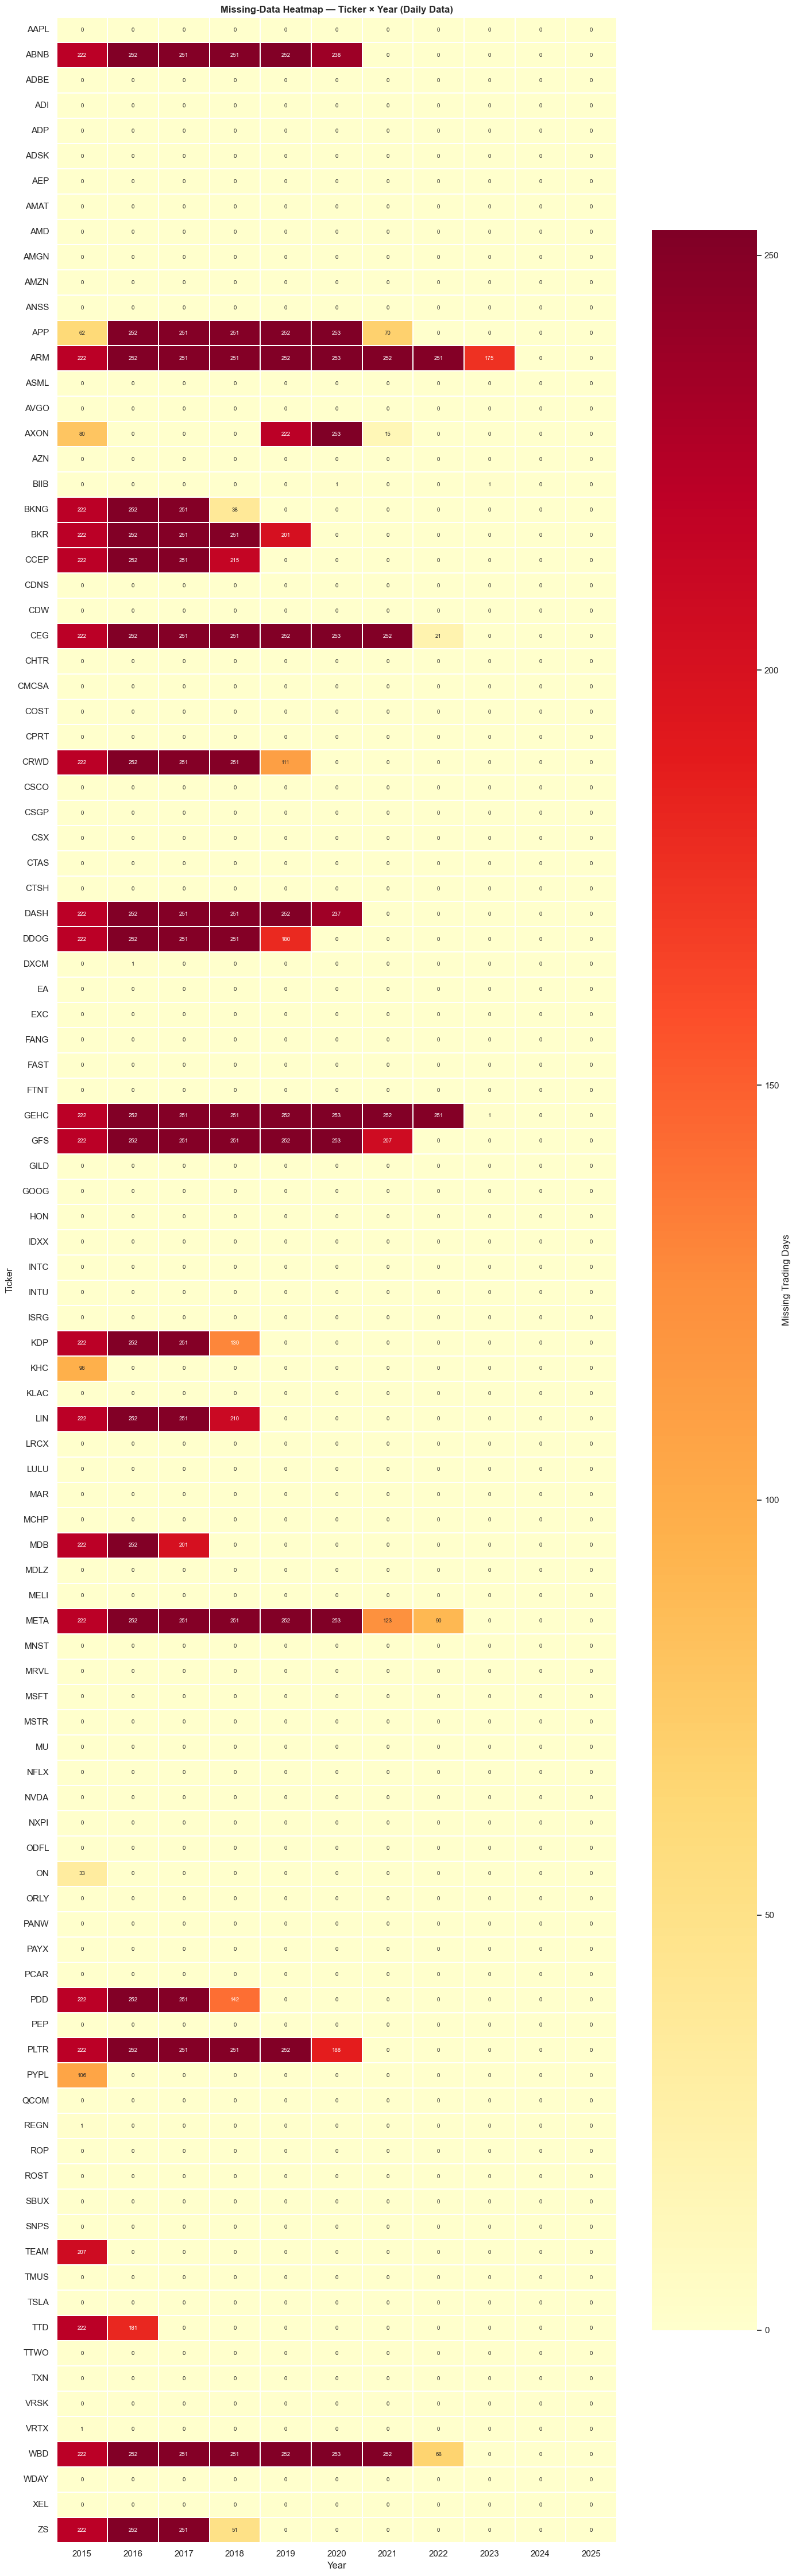

In [6]:
# "Missing days" = trading days (union of all observed days) without a row for that ticker
all_days_df = pd.DataFrame({"date": all_trading_days})
all_days_df["year"] = pd.to_datetime(all_days_df["date"]).dt.year
trading_days_per_year = all_days_df.groupby("year").size()

records = []
for ticker, observed in all_daily_sets.items():
    obs_df = pd.DataFrame({"date": sorted(observed)})
    obs_df["year"] = pd.to_datetime(obs_df["date"]).dt.year
    obs_per_year = obs_df.groupby("year").size()
    missing = (trading_days_per_year - obs_per_year).fillna(trading_days_per_year).clip(lower=0)
    for year, miss in missing.items():
        records.append({"Ticker": ticker, "Year": year, "Missing Days": int(miss)})

heatmap_data = (pd.DataFrame(records)
                .pivot(index="Ticker", columns="Year", values="Missing Days").fillna(0))

fig, ax = plt.subplots(figsize=(max(14, len(heatmap_data.columns) * 0.9), max(8, len(all_tickers) * 0.45)))
sns.heatmap(heatmap_data, ax=ax, cmap="YlOrRd", linewidths=0.3, annot=True, fmt=".0f",
            annot_kws={"size": 7}, cbar_kws={"label": "Missing Trading Days"})
ax.set_title("Missing-Data Heatmap — Ticker × Year (Daily Data)", fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("Ticker")
plt.tight_layout()
plt.savefig(FIGURES / "03_missing_data_heatmap_daily.png", bbox_inches="tight", dpi=150)
plt.show()

In the heatmap, most "missing" days are years before a ticker's IPO or index listing (e.g. ARM, CEG, GEHC). Gaps *inside* a ticker's own history are rare and are listed in the "Missing Days" table of section 1. In the original course dataset they come from ticker-symbol reuse: before AppLovin listed in April 2021, the symbol APP belonged to a different penny stock, which leaves a multi-year gap and one spurious +57,959% "return" on the switch day (AXON shows the same pattern; META's gap is the 2022 FB→META rename). The modelling pipeline handles gaps by invalidating the next-day label of the last row before a gap (`flag_pregap_rows`, and the gap-aware label in `src/storage.py`).

## 5. Class balance: up vs down days per ticker

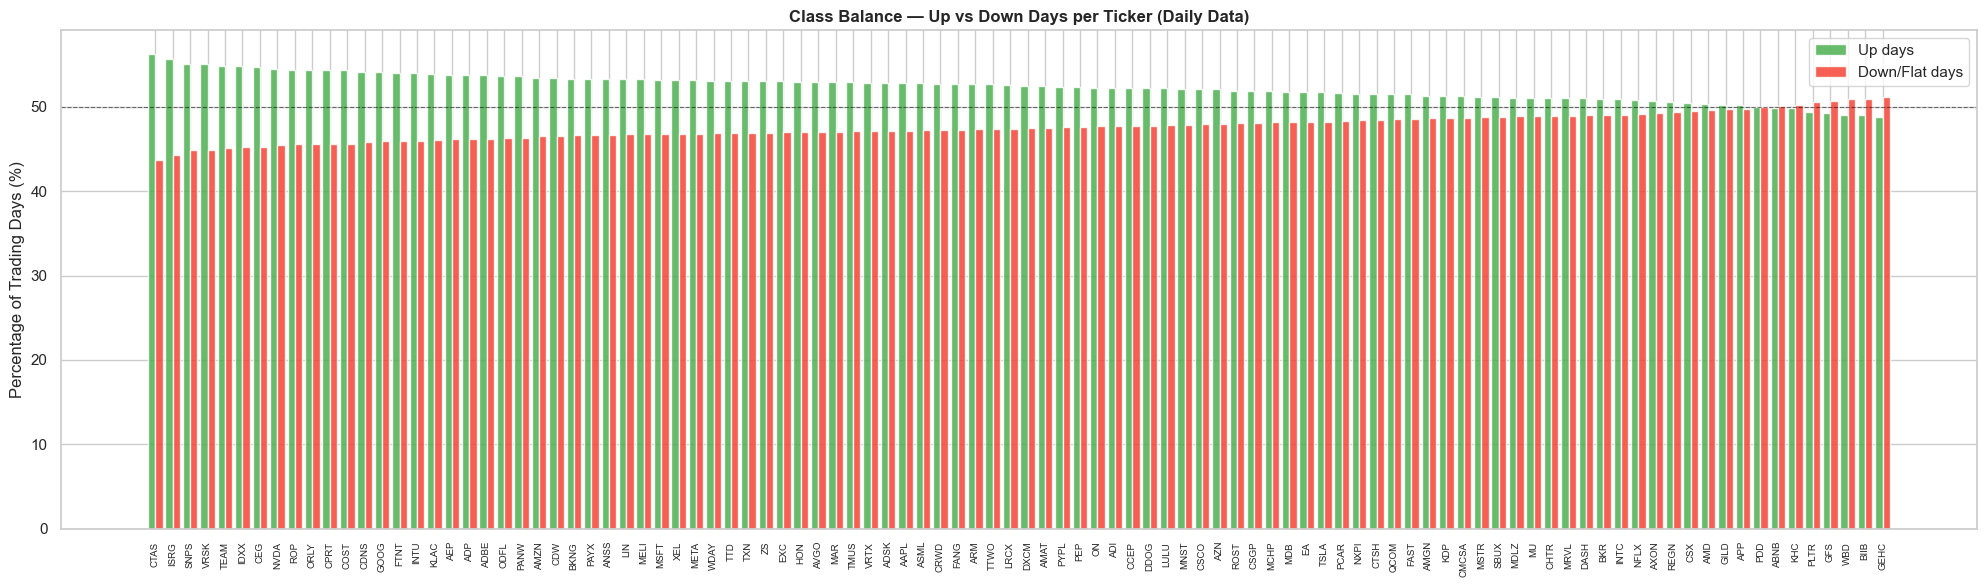

Share of up days across all ticker-days: 0.525


In [7]:
# Class: 1 = up day (return > 0), 0 = down/flat day
bal_df = stats_df[["Ticker", "Pct Up Days (%)", "Pct Down/Flat (%)"]].rename(
    columns={"Pct Up Days (%)": "Up (%)", "Pct Down/Flat (%)": "Down/Flat (%)"}
).sort_values("Up (%)", ascending=False)

fig, ax = plt.subplots(figsize=(20, 6))
x = np.arange(len(bal_df))
width = 0.42
ax.bar(x - width / 2, bal_df["Up (%)"], width, label="Up days", color="#4CAF50", alpha=0.85)
ax.bar(x + width / 2, bal_df["Down/Flat (%)"], width, label="Down/Flat days", color="#F44336", alpha=0.85)
ax.axhline(50, color="black", linewidth=0.8, linestyle="--", alpha=0.5)
ax.set_xticks(x); ax.set_xticklabels(bal_df["Ticker"], rotation=90, fontsize=7)
ax.set_ylabel("Percentage of Trading Days (%)")
ax.set_title("Class Balance — Up vs Down Days per Ticker (Daily Data)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "04_class_balance_daily.png", bbox_inches="tight", dpi=150)
plt.show()

print(f"Share of up days across all ticker-days: {(combined_returns > 0).mean():.3f}")